## Import

In [1]:
import json, os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

## Setup

In [2]:
SEED = 42
np.random.seed(SEED)
assert os.path.exists("weights_V4_0/regression_pytorch_test_metrics.json"), "pytorch twin must run first (epochs come from it)"
ORA = {r["model"]: r for r in json.load(open("weights_V4_0/regression_pytorch_test_metrics.json"))["models"]}
os.makedirs("weights_V4_0", exist_ok=True)
DELTA, NF = 0.5, 13
VARS = {"ReLU (baseline)": dict(ffn="relu", hid=64), "ReGLU, same hidden": dict(ffn="reglu", hid=64), "ReGLU, param-matched": dict(ffn="reglu", hid=38)}
NAME = "NAM (log1p + Huber) | "

In [3]:
df = pd.read_csv("marketing_campaign.csv", sep="\t")
df = df.drop(columns=["ID", "Z_CostContact", "Z_Revenue"])
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y")
ref_date = df["Dt_Customer"].max()
df["Customer_Tenure_Days"] = (ref_date - df["Dt_Customer"]).dt.days
df["Age"] = 2014 - df["Year_Birth"]
df = df[~df["Year_Birth"].isin([1893, 1899, 1900])].copy()
df = df[df["Income"] != 666666].copy()  # drop $666,666 income outlier (same treatment as Year_Birth sentinels)
df["Marital_Status"] = df["Marital_Status"].replace({"Absurd": "Single", "YOLO": "Single", "Alone": "Single"})
df = df.dropna(subset=["Income"]).copy()
REG_FEATURES = ["NumCatalogPurchases","MntMeatProducts","MntWines","NumWebVisitsMonth","MntSweetProducts",
    "MntFruits","NumWebPurchases","MntGoldProds","NumStorePurchases","MntFishProducts","Kidhome","Age","NumDealsPurchases"]
X_full = df[REG_FEATURES].values; y_raw = df["Income"].values.astype(float)
print(f"features: {len(REG_FEATURES)} dims | NAM delta={DELTA} | log1p target, Huber loss (robust to right-skewed income)")

features: 13 dims | NAM delta=0.5 | log1p target, Huber loss (robust to right-skewed income)


## Dataloader

In [4]:
X_temp, X_test_raw, y_temp_raw, y_test_raw = train_test_split(X_full, y_raw, test_size=0.20, random_state=SEED)
scaler = StandardScaler().fit(X_temp)
Xtr = scaler.transform(X_temp).astype(np.float64); Xte = scaler.transform(X_test_raw).astype(np.float64)
y_temp_log = np.log1p(y_temp_raw).reshape(-1, 1); y_test_log = np.log1p(y_test_raw).reshape(-1, 1)
y_scaler = StandardScaler().fit(y_temp_log)
ytr_z = y_scaler.transform(y_temp_log).ravel().astype(np.float64)
yte_z = y_scaler.transform(y_test_log).ravel().astype(np.float64)
MU, SIG = float(y_scaler.mean_[0]), float(y_scaler.scale_[0])
print(f"train {Xtr.shape} test {Xte.shape} | y_log scaler: mean {MU:.4f} scale {SIG:.4f}")

train (1769, 13) test (443, 13) | y_log scaler: mean 10.7459 scale 0.5066


## Model

In [5]:
def init_params(ffn, hid):
    """ReLU: W1 is (F, 1, hid). ReGLU: W1 is (F, 1, 2*hid) = [value | gate]."""
    global FFN, HH, HW, P_
    FFN, HH = ffn, hid; HW = hid if ffn == "relu" else 2 * hid
    P_ = {}
    P_["W1"] = np.random.randn(NF, 1, HW) * np.sqrt(2.0 / 1.0); P_["b1"] = np.zeros((NF, HW))
    P_["W2"] = np.random.randn(NF, HH, 1) * np.sqrt(2.0 / HH); P_["b2"] = np.zeros((NF, 1))
    P_["b0"] = np.zeros(1)
    return P_
for v, s in VARS.items():
    print(f"{v:22s} scratch parameters: {sum(a.size for a in init_params(**s).values())}")

ReLU (baseline)        scratch parameters: 2510
ReGLU, same hidden     scratch parameters: 4174
ReGLU, param-matched   scratch parameters: 2484


In [6]:
def act(Z1):
    if FFN == "reglu": return Z1[..., :HH] * np.maximum(Z1[..., HH:], 0)      # value * ReLU(gate)
    return np.maximum(Z1, 0)
def fwd(Xb):
    B = Xb.shape[0]
    Z1 = Xb[:, :, None] * P_["W1"][:, 0, :][None, :, :] + P_["b1"][None, :, :]  # (B,F,HW)
    A1 = act(Z1)
    Fj = np.einsum("bfh,fh->bf", A1, P_["W2"][:, :, 0]) + P_["b2"].ravel()  # (B,F)
    pred = Fj.sum(1, keepdims=True) + P_["b0"]
    return pred, (Xb, Z1, A1, Fj)

In [7]:
def huber(pred, y):
    e = (pred.ravel() - y.ravel()); B = len(e)
    q = np.abs(e) <= DELTA  # tie -> quadratic branch (torch parity)
    loss = np.where(q, 0.5 * e ** 2, DELTA * (np.abs(e) - 0.5 * DELTA)).mean()
    dp = np.where(q, e, DELTA * np.sign(e)).reshape(-1, 1) / B
    return float(loss), dp

In [8]:
def bwd(dp, cache, G):
    Xb, Z1, A1, Fj = cache; B = Xb.shape[0]
    G["b0"] += dp.sum(0)
    dF = np.broadcast_to(dp, (B, NF))                       # dF[b,f]
    G["b2"] += dF.sum(0).reshape(NF, 1)
    G["W2"] += np.einsum("bfh,bf->fh", A1, dF)[:, :, None]  # dW2[f,h,0] = sum_b A1*dF
    dA = dF[:, :, None] * P_["W2"][None, :, :, 0]            # dA[b,f,h] = dF*W2
    if FFN == "reglu":
        val, gate = Z1[..., :HH], Z1[..., HH:]
        dZ = np.concatenate([dA * np.maximum(gate, 0), dA * val * (gate > 0)], axis=-1)
    else:
        dZ = dA * (Z1 > 0)
    G["b1"] += dZ.sum(0)
    G["W1"] += np.einsum("bf,bfh->fh", Xb, dZ)[:, None, :]

## Sanity Check

In [9]:
init_params(**VARS["ReGLU, param-matched"])
Xc, yc = Xtr[:2], ytr_z[:2]
p0, c0 = fwd(Xc); _, dp0 = huber(p0, yc)
G0 = {k: np.zeros_like(a) for k, a in P_.items()}; bwd(dp0, c0, G0)
for key, idx in [("W2", (0, 0, 0)), ("W1", (1, 0, 3)), ("W1", (1, 0, HH + 3)), ("b1", (4, HH + 2)), ("b2", (2, 0))]:
    e = 1e-5; old = P_[key][idx]
    P_[key][idx] = old + e; lp = huber(fwd(Xc)[0], yc)[0]
    P_[key][idx] = old - e; lm = huber(fwd(Xc)[0], yc)[0]
    P_[key][idx] = old
    num, ana = (lp - lm) / (2 * e), G0[key][idx]
    err = abs(num - ana) / (abs(num) + abs(ana) + 1e-12)
    print(f"check {key}{list(idx)}: numeric {num:.6e} analytic {ana:.6e} | relerr {err:.2e}")
    assert err < 1e-4, "backward pass does not match the numeric slope"

check W2[0, 0, 0]: numeric 0.000000e+00 analytic 0.000000e+00 | relerr 0.00e+00
check W1[1, 0, 3]: numeric -3.145172e-01 analytic -3.145172e-01 | relerr 1.99e-11
check W1[1, 0, 41]: numeric -6.348411e-01 analytic -6.348411e-01 | relerr 2.64e-11
check b1[4, 40]: numeric 0.000000e+00 analytic 0.000000e+00 | relerr 0.00e+00
check b2[2, 0]: numeric 5.000000e-01 analytic 5.000000e-01 | relerr 2.55e-11


## Training

In [10]:
LR0, WD, B1, B2, EP = 1e-3, 1e-4, 0.9, 0.999, 1e-8
def to_dollar(z): return np.expm1(np.clip(np.asarray(z).ravel() * SIG + MU, 0.0, 15.0))
def train_huber():
    tot = 0.0
    for i in range(0, len(Xtr), 256):
        p, _ = fwd(Xtr[i:i+256]); l, _ = huber(p, ytr_z[i:i+256]); tot += l * (min(i + 256, len(Xtr)) - i)
    return tot / len(Xtr)

runs = {}
for vname, spec in VARS.items():
    np.random.seed(SEED + 7)
    init_params(**spec)
    E = int(ORA[NAME + vname]["epochs"])                  # epoch count chosen by the pytorch twin's inner validation
    M = {k: np.zeros_like(a) for k, a in P_.items()}; V = {k: np.zeros_like(a) for k, a in P_.items()}
    N = len(Xtr); step = 0; hist = []
    for epoch in range(1, E + 1):
        lr = 0.5 * LR0 * (1 + np.cos(np.pi * (epoch - 1) / 100))
        perm = np.random.permutation(N)
        for i in range(0, N, 64):
            idx = perm[i:i+64]
            pred, cache = fwd(Xtr[idx]); _, dp = huber(pred, ytr_z[idx])
            G = {k: np.zeros_like(a) for k, a in P_.items()}
            bwd(dp, cache, G); step += 1
            for k in P_:
                g = G[k] + WD * P_[k]
                M[k] = B1 * M[k] + (1 - B1) * g; V[k] = B2 * V[k] + (1 - B2) * (g ** 2)
                mh = M[k] / (1 - B1 ** step); vh = V[k] / (1 - B2 ** step)
                P_[k] -= lr * (mh / (np.sqrt(vh) + EP))
        hist.append(train_huber())
    runs[vname] = dict(P={k: a.copy() for k, a in P_.items()}, E=E, hist=hist)
    print(f"{vname:22s} trained {E} epochs | final train Huber {hist[-1]:.4f}")

ReLU (baseline)        trained 95 epochs | final train Huber 0.0838


ReGLU, same hidden     trained 97 epochs | final train Huber 0.0774


ReGLU, param-matched   trained 97 epochs | final train Huber 0.0781


## Evaluation

In [11]:
results, scores, history = [], {}, {}
for vname, spec in VARS.items():
    FFN, HH = spec["ffn"], spec["hid"]; HW = HH if FFN == "relu" else 2 * HH
    P_ = runs[vname]["P"]
    d = to_dollar(fwd(Xte)[0]); scores[vname] = d
    mse = float(mean_squared_error(y_test_raw, d))
    results.append(dict(model=NAME + vname, tier="extracurricular", selection="inner validation",
        r2=round(float(r2_score(y_test_raw, d)), 4), rmse=round(float(np.sqrt(mse)), 1), mae=round(float(mean_absolute_error(y_test_raw, d)), 1),
        mse=round(mse, 1), epochs=runs[vname]["E"], n_params=int(sum(a.size for a in P_.values()))))
    history[vname] = runs[vname]["hist"]
table = pd.DataFrame(results)
print(table.drop(columns=["tier", "selection"]).to_string(index=False))
json.dump({"n_test": int(len(y_test_raw)), "seed": SEED, "models": results}, open("weights_V4_0/regression_scratch_test_metrics.json", "w"), indent=2)
np.savez("weights_V4_0/regression_scratch_test_scores.npz", y_true=y_test_raw, **scores)
np.savez("weights_V4_0/regression_scratch.npz", **{f"{v}|{k}": a for v, r in runs.items() for k, a in r["P"].items()})
pd.DataFrame({v: pd.Series(h) for v, h in history.items()}).rename_axis("epoch").to_csv("weights_V4_0/regression_scratch_history.csv")

                                     model     r2    rmse    mae         mse  epochs  n_params
     NAM (log1p + Huber) | ReLU (baseline) 0.7212 11507.7 7176.0 132426146.9      95      2510
  NAM (log1p + Huber) | ReGLU, same hidden 0.7558 10769.3 6881.4 115977225.4      97      4174
NAM (log1p + Huber) | ReGLU, param-matched 0.7570 10743.0 6911.4 115411520.0      97      2484


## Parity Check

In [12]:
import warnings
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             log_loss, average_precision_score, mean_squared_error, mean_absolute_error, r2_score)
warnings.filterwarnings("ignore")
torch.set_num_threads(1)

device = torch.device("cpu")
device = torch.device("cpu")


class SubNet(nn.Module):
    """One feature -> one number. ffn='relu': Linear(1,hid)-ReLU-Linear(hid,1).
       ffn='reglu': Linear(1,2*hid) split into (value, gate) -> value * ReLU(gate) -> Linear(hid,1)."""
    def __init__(self, ffn="relu", hid=64):
        super().__init__()
        self.ffn = ffn
        self.fc1 = nn.Linear(1, hid if ffn == "relu" else 2 * hid); self.fc2 = nn.Linear(hid, 1); self.relu = nn.ReLU()
        nn.init.kaiming_normal_(self.fc1.weight, nonlinearity="relu"); nn.init.zeros_(self.fc1.bias)
        nn.init.kaiming_normal_(self.fc2.weight, nonlinearity="relu"); nn.init.zeros_(self.fc2.bias)
    def forward(self, xj):
        z = self.fc1(xj)
        if self.ffn == "reglu":
            val, gate = z.chunk(2, dim=-1); a = val * self.relu(gate)
        else:
            a = self.relu(z)
        return self.fc2(a)

class NAM(nn.Module):
    def __init__(self, n_feat=13, ffn="relu", hid=64):
        super().__init__()
        self.subs = nn.ModuleList([SubNet(ffn, hid) for _ in range(n_feat)])
        self.b0 = nn.Parameter(torch.zeros(1))
    def forward(self, x):
        return sum(sub(x[:, j:j + 1]) for j, sub in enumerate(self.subs)) + self.b0

# ReLU baseline: hidden 64 (193 parameters per subnet). ReGLU "same hidden": 64 (321 per subnet).
# ReGLU "param-matched": hidden 38 (191 per subnet, closest to 193).
VARIANTS = {
    "ReLU (baseline)":       dict(ffn="relu", hid=64),
    "ReGLU, same hidden":    dict(ffn="reglu", hid=64),
    "ReGLU, param-matched":  dict(ffn="reglu", hid=38),
}
DELTA = 0.5   # Huber delta (log-z space), as V2_0
def make_model(v, seed):
    torch.manual_seed(seed)
    return NAM(n_feat=len(REG_FEATURES), **VARIANTS[v]).to(device)


def load_into_torch(m, Pn):
    with torch.no_grad():
        for f, sub in enumerate(m.subs):
            sub.fc1.weight.copy_(torch.tensor(Pn["W1"][f, 0, :]).view(-1, 1)); sub.fc1.bias.copy_(torch.tensor(Pn["b1"][f]))
            sub.fc2.weight.copy_(torch.tensor(Pn["W2"][f, :, 0]).view(1, -1)); sub.fc2.bias.copy_(torch.tensor(Pn["b2"][f]))
        m.b0.copy_(torch.tensor(Pn["b0"]))

xb, yb_ = Xtr[:64], ytr_z[:64]
for vname, spec in VARS.items():
    FFN, HH = spec["ffn"], spec["hid"]; HW = HH if FFN == "relu" else 2 * HH
    P_ = runs[vname]["P"]
    m = make_model(vname, 0).double().eval(); load_into_torch(m, P_)
    pt = m(torch.tensor(xb)); loss_t = nn.HuberLoss(delta=DELTA)(pt, torch.tensor(yb_).view(-1, 1)); loss_t.backward()
    ps, cache = fwd(xb); loss_s, dp = huber(ps, yb_)
    G = {k: np.zeros_like(a) for k, a in P_.items()}; bwd(dp, cache, G)
    d_out = float(np.abs(pt.detach().numpy() - ps).max()); d_loss = abs(float(loss_t) - loss_s)
    g_t = {"W1": np.stack([s.fc1.weight.grad.numpy().ravel() for s in m.subs])[:, None, :], "b1": np.stack([s.fc1.bias.grad.numpy() for s in m.subs]),
           "W2": np.stack([s.fc2.weight.grad.numpy().ravel() for s in m.subs])[:, :, None], "b2": np.stack([s.fc2.bias.grad.numpy() for s in m.subs]), "b0": m.b0.grad.numpy()}
    d_grad = max(float(np.abs(g_t[k] - G[k]).max() / (np.abs(g_t[k]).max() + 1e-12)) for k in G)
    print(f"{vname:22s} | max|dpred| {d_out:.2e} | dloss {d_loss:.2e} | max rel grad diff {d_grad:.2e}")
    assert d_out < 1e-8 and d_loss < 1e-8 and d_grad < 1e-6, "scratch and PyTorch disagree on identical weights"
    assert sum(a.size for a in P_.values()) == ORA[NAME + vname]["n_params"], "parameter count differs from the pytorch twin"
print("scratch forward and backward match PyTorch on identical weights; parameter counts match")
for r in results:
    o_ = ORA[r["model"]]
    print(f"{r['model']:44s} dR2 {abs(r['r2'] - o_['r2']):.4f} (different random init, same recipe)")
    assert abs(r["r2"] - o_["r2"]) < 0.05

ReLU (baseline)        | max|dpred| 3.11e-15 | dloss 5.55e-17 | max rel grad diff 4.08e-15
ReGLU, same hidden     | max|dpred| 9.33e-15 | dloss 1.67e-16 | max rel grad diff 1.11e-14
ReGLU, param-matched   | max|dpred| 1.33e-14 | dloss 8.33e-17 | max rel grad diff 4.07e-15
scratch forward and backward match PyTorch on identical weights; parameter counts match
NAM (log1p + Huber) | ReLU (baseline)        dR2 0.0018 (different random init, same recipe)
NAM (log1p + Huber) | ReGLU, same hidden     dR2 0.0063 (different random init, same recipe)
NAM (log1p + Huber) | ReGLU, param-matched   dR2 0.0121 (different random init, same recipe)


## Loss Curve

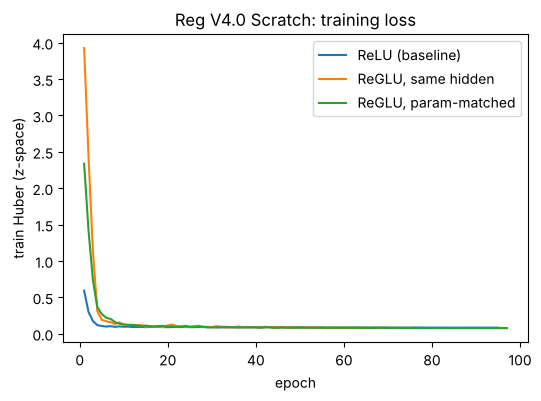

In [13]:
import matplotlib.pyplot as plt
os.makedirs("media", exist_ok=True)
plt.figure(figsize=(6, 4))
for v, h in history.items(): plt.plot(range(1, len(h) + 1), h, label=v)
plt.xlabel("epoch"); plt.ylabel("train Huber (z-space)"); plt.legend(); plt.title("Reg V4.0 Scratch: training loss")
plt.savefig("media/loss_reg_V4_0.png", dpi=150); plt.show()